In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
import pandas as pd
import numpy as np
from IPython.display import Image
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from matplotlib.pyplot import imread
import tf_keras
import datetime

labels_csv = pd.read_csv('/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/labels.csv')
#print(labels_csv['breed'].value_counts().plot.bar(figsize=(20,10)))
#print(labels_csv['breed'].value_counts().median())
#Image('/content/drive/MyDrive/dog-breed-identification/train/000bec180eb18c7604dcecc8fe0dba07.jpg')
filenames = ['/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/train/'+fname + '.jpg' for fname in labels_csv['id']]
labels = labels_csv['breed']
labels = np.array(labels)
#Find the unique number of labels
unique_breeds = np.unique(labels)
#Turn every label into boolean array
boolean_labels = [label == unique_breeds for label in labels]
x = filenames
y = boolean_labels
#We are going to start with ~1000 images and increase as we need
NUM_IMAGES = 1000
#Let us split our data into training and validation set
np.random.seed(42)
x_train, x_val, y_train, y_val = train_test_split(x[:NUM_IMAGES], y[:NUM_IMAGES], test_size=0.2)
#Pre-process our images to turn them into tensors
IMAGE_SIZE = 224
#Create a function for pre-processing images
def process_image(image_path, img_size=IMAGE_SIZE):
  image = tf.io.read_file(image_path)

  #Turn the jpg image to numerical tensor with 3 color channels (R-G-B)
  image = tf.image.decode_jpeg(image, channels=3)

  #Convert the color channels from 0-255 to 0-1 values
  image = tf.image.convert_image_dtype(image, tf.float32)

  #Resize the image to (224,224)
  image = tf.image.resize(image, size=[IMAGE_SIZE, IMAGE_SIZE])

  return image
#Turning our data into batches
#Create a simple function to return a tuple (image, label)
def get_image_label(image_path, label):
  image = process_image(image_path)
  return (image, label)
BATCH_SIZE = 32
def create_data_batches(x, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
  '''
  Creates batches of data out of image(x) and label(y) pairs.
  Shuffles the data if it's training pairs but not if it's validation data
  Also accepts test data as input (no labels).
  '''

  #If the dataset is test data, then we don't have labels
  if test_data:
    print('Creating test data batches...')
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x)))
    data_batch = data.map(process_image).batch(BATCH_SIZE)
    return data_batch

  elif valid_data:
    print('Creating validation data batches...')
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x), #filepaths
                                               tf.constant(y))) #labels

    data_batch = data.map(get_image_label).batch(BATCH_SIZE)
    return data_batch

  else:
    print('Create training data batches...')
    #Turn filepaths and labels into tensors
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x), tf.constant(y)))
    #Shuffling path names and labels before mapping image processor function
    data = data.shuffle(buffer_size = len(x))
    #Create (image,label) tuples (this also turns image path into preprocessed image)
    data = data.map(get_image_label)
    #Turn training data into batches
    data_batch = data.batch(BATCH_SIZE)

    return data_batch
#Create training and validation data batches
train_data = create_data_batches(x_train, y_train)
val_data = create_data_batches(x_val, y_val, valid_data=True)
#Create a function to view images in a data batch
def show_25_images(images, labels):
  plt.figure(figsize=(10,10))

  for i in range(25):
    ax = plt.subplot(5,5,i+1)
    plt.imshow(images[i])
    plt.title(unique_breeds[labels[i].argmax()])
    plt.axis('off')
train_images, train_labels = next(train_data.as_numpy_iterator())
# show_25_images(train_images, train_labels)
##Building a MODEL
#Setup input shape of the model
INPUT_SHAPE = [None, 224, 224, 3]
#Setup output shape of the model
OUTPUT_SHAPE = len(unique_breeds)
#Setup Model URL from Tensorflow Hub
MODEL_URL = 'https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1'
#tf_keras is a high level API for building and training high level machine learning models
#Create a function which builds a Keras model
def create_model(input_shape=INPUT_SHAPE, output_shape=OUTPUT_SHAPE, model_url=MODEL_URL):
  print('Building model with  ', model_url)

  #Setup the model layers
  model = tf_keras.Sequential([
      hub.KerasLayer(model_url), #Layer 1: Input Layer
      tf_keras.layers.Dense(units=output_shape, activation='softmax'), #Layer 2: Output Layer

  ])
  #Compile the model
  model.compile(
      loss = tf_keras.losses.CategoricalCrossentropy(),
      optimizer = tf_keras.optimizers.Adam(),
      metrics = ['accuracy']
  )
  #Build the model
  model.build(INPUT_SHAPE)
  return model
# model = create_model()
# model.summary()
#Load TensorBoard notebook extension
%load_ext tensorboard
#Create a function to build a tensorboard callback
def create_tensorboard_callback():
  #Create a log directory for storing Tensorboard logs
  logdir = os.path.join('/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/logs', datetime.datetime.now().strftime('%Y%m%d-%H%M%S'))

  return tf_keras.callbacks.TensorBoard(logdir)
early_stopping = tf_keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3)
#Training a model on a subset of data
NUM_EPOCHS = 100
'''
Let's create a function which trains a model
1) Create a model using 'create_model()'
2) Setup a TensorBoard callback using 'create_tensorboard_callback()'
3) Call the 'fit()' on our model passing it the training data, validation data, no. of
epochs and the callbacks we would like to use.
4) Return the model
'''
def train_model():
  model = create_model()
  tensorboard = create_tensorboard_callback()

  model.fit(x=train_data, epochs=NUM_EPOCHS, validation_data=val_data, validation_freq=1, callbacks=[tensorboard, early_stopping])

  return model
#Fit the model to the data
model = train_model()

In [2]:
predictions = model.predict(val_data, verbose=1)
print(predictions.shape)

7/7 [==============================] - 1s 167ms/step
(200, 120)


In [3]:
import numpy as np
#First prediction
index = 70
#print(predictions[index])
print(f'Max value (probability of prediction): ',np.max(predictions[index]))
print(f'Sum: {np.sum(predictions[index])}')
print(f'Max Index: {np.argmax(predictions[index])}')
print(f'Predicted Label: {unique_breeds[np.argmax(predictions[index])]}')

Max value (probability of prediction):  0.9274918
Sum: 1.000000238418579
Max Index: 74
Predicted Label: mexican_hairless


In [4]:
#Turn prediction probabilities into respective labels
def get_pred_label(prediction_probabilities):
  return unique_breeds[np.argmax(prediction_probabilities)]

#Get a predicted label based on array of prediction possibility
pred_label = get_pred_label(predictions[10])
print(pred_label)

yorkshire_terrier


In [5]:
#Create a function to unbatch a Batch dataset
images = []
labels = []

def unbatchify(data):
  for image, label in data.unbatch().as_numpy_iterator():
    images.append(image)
    labels.append(unique_breeds[np.argmax(label)])

  return images, labels

#Unbatchify the validation dataset
val_images, val_labels = unbatchify(val_data)

#print(val_images[0], val_labels[0])
get_pred_label(val_images[0])


2025-05-11 10:38:27.323208: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


'vizsla'

In [7]:
import numpy as np

def plot_pred(prediction_probabilities, labels, images, n=8):
  pred_prob, true_label, image = prediction_probabilities[n], labels[n], images[n]

  #Get the pred label
  pred_label = get_pred_label(pred_prob)

  #Plot image and remove ticks
  plt.imshow(image)
  plt.xticks([])
  plt.yticks([])

  if pred_label == true_label:
    color = 'green'
  else:
    color = 'red'

  plt.title('{}  {:2.0f}%  {}'.format(pred_label, np.max(pred_prob*100), true_label), color=color)

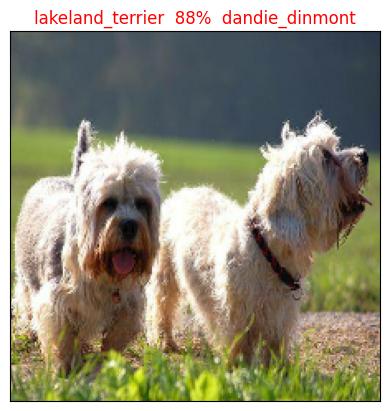

In [8]:
plot_pred(predictions, val_labels, val_images, n=65)

In [9]:
def plot_pred_conf(prediction_probabilities, labels, n=1):
  #Plot the top 10 highest prediction confidences along with truth table for sample n
  pred_prob, true_label = prediction_probabilities[n], labels[n]

  #Get the predicted label
  pred_label = get_pred_label(pred_prob)

  #Find the top 10 prediction confidence indexes
  top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]

  #Get the top 10 prediction confidence values
  top_10_pred_values = pred_prob[top_10_pred_indexes]

  #Find the top 10 prediction labels
  top_10_pred_labels = unique_breeds[top_10_pred_indexes]

  #Setup plot
  top_plot = plt.bar(np.arange(len(top_10_pred_labels)), top_10_pred_values, color='grey')
  plt.xticks(np.arange(len(top_10_pred_labels)), labels= top_10_pred_labels, rotation='vertical')




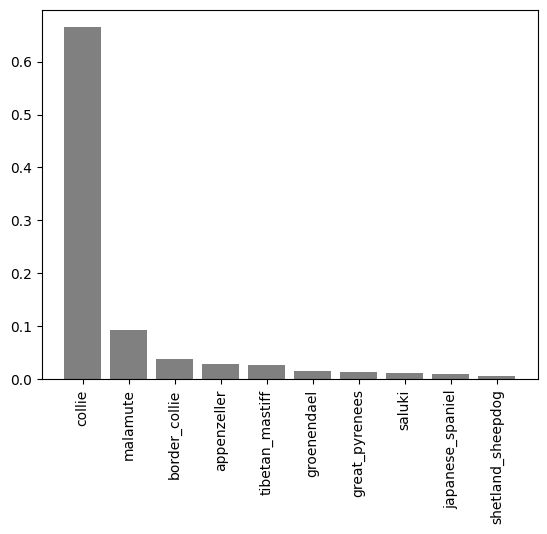

In [10]:
plot_pred_conf(predictions, val_labels, n=9)

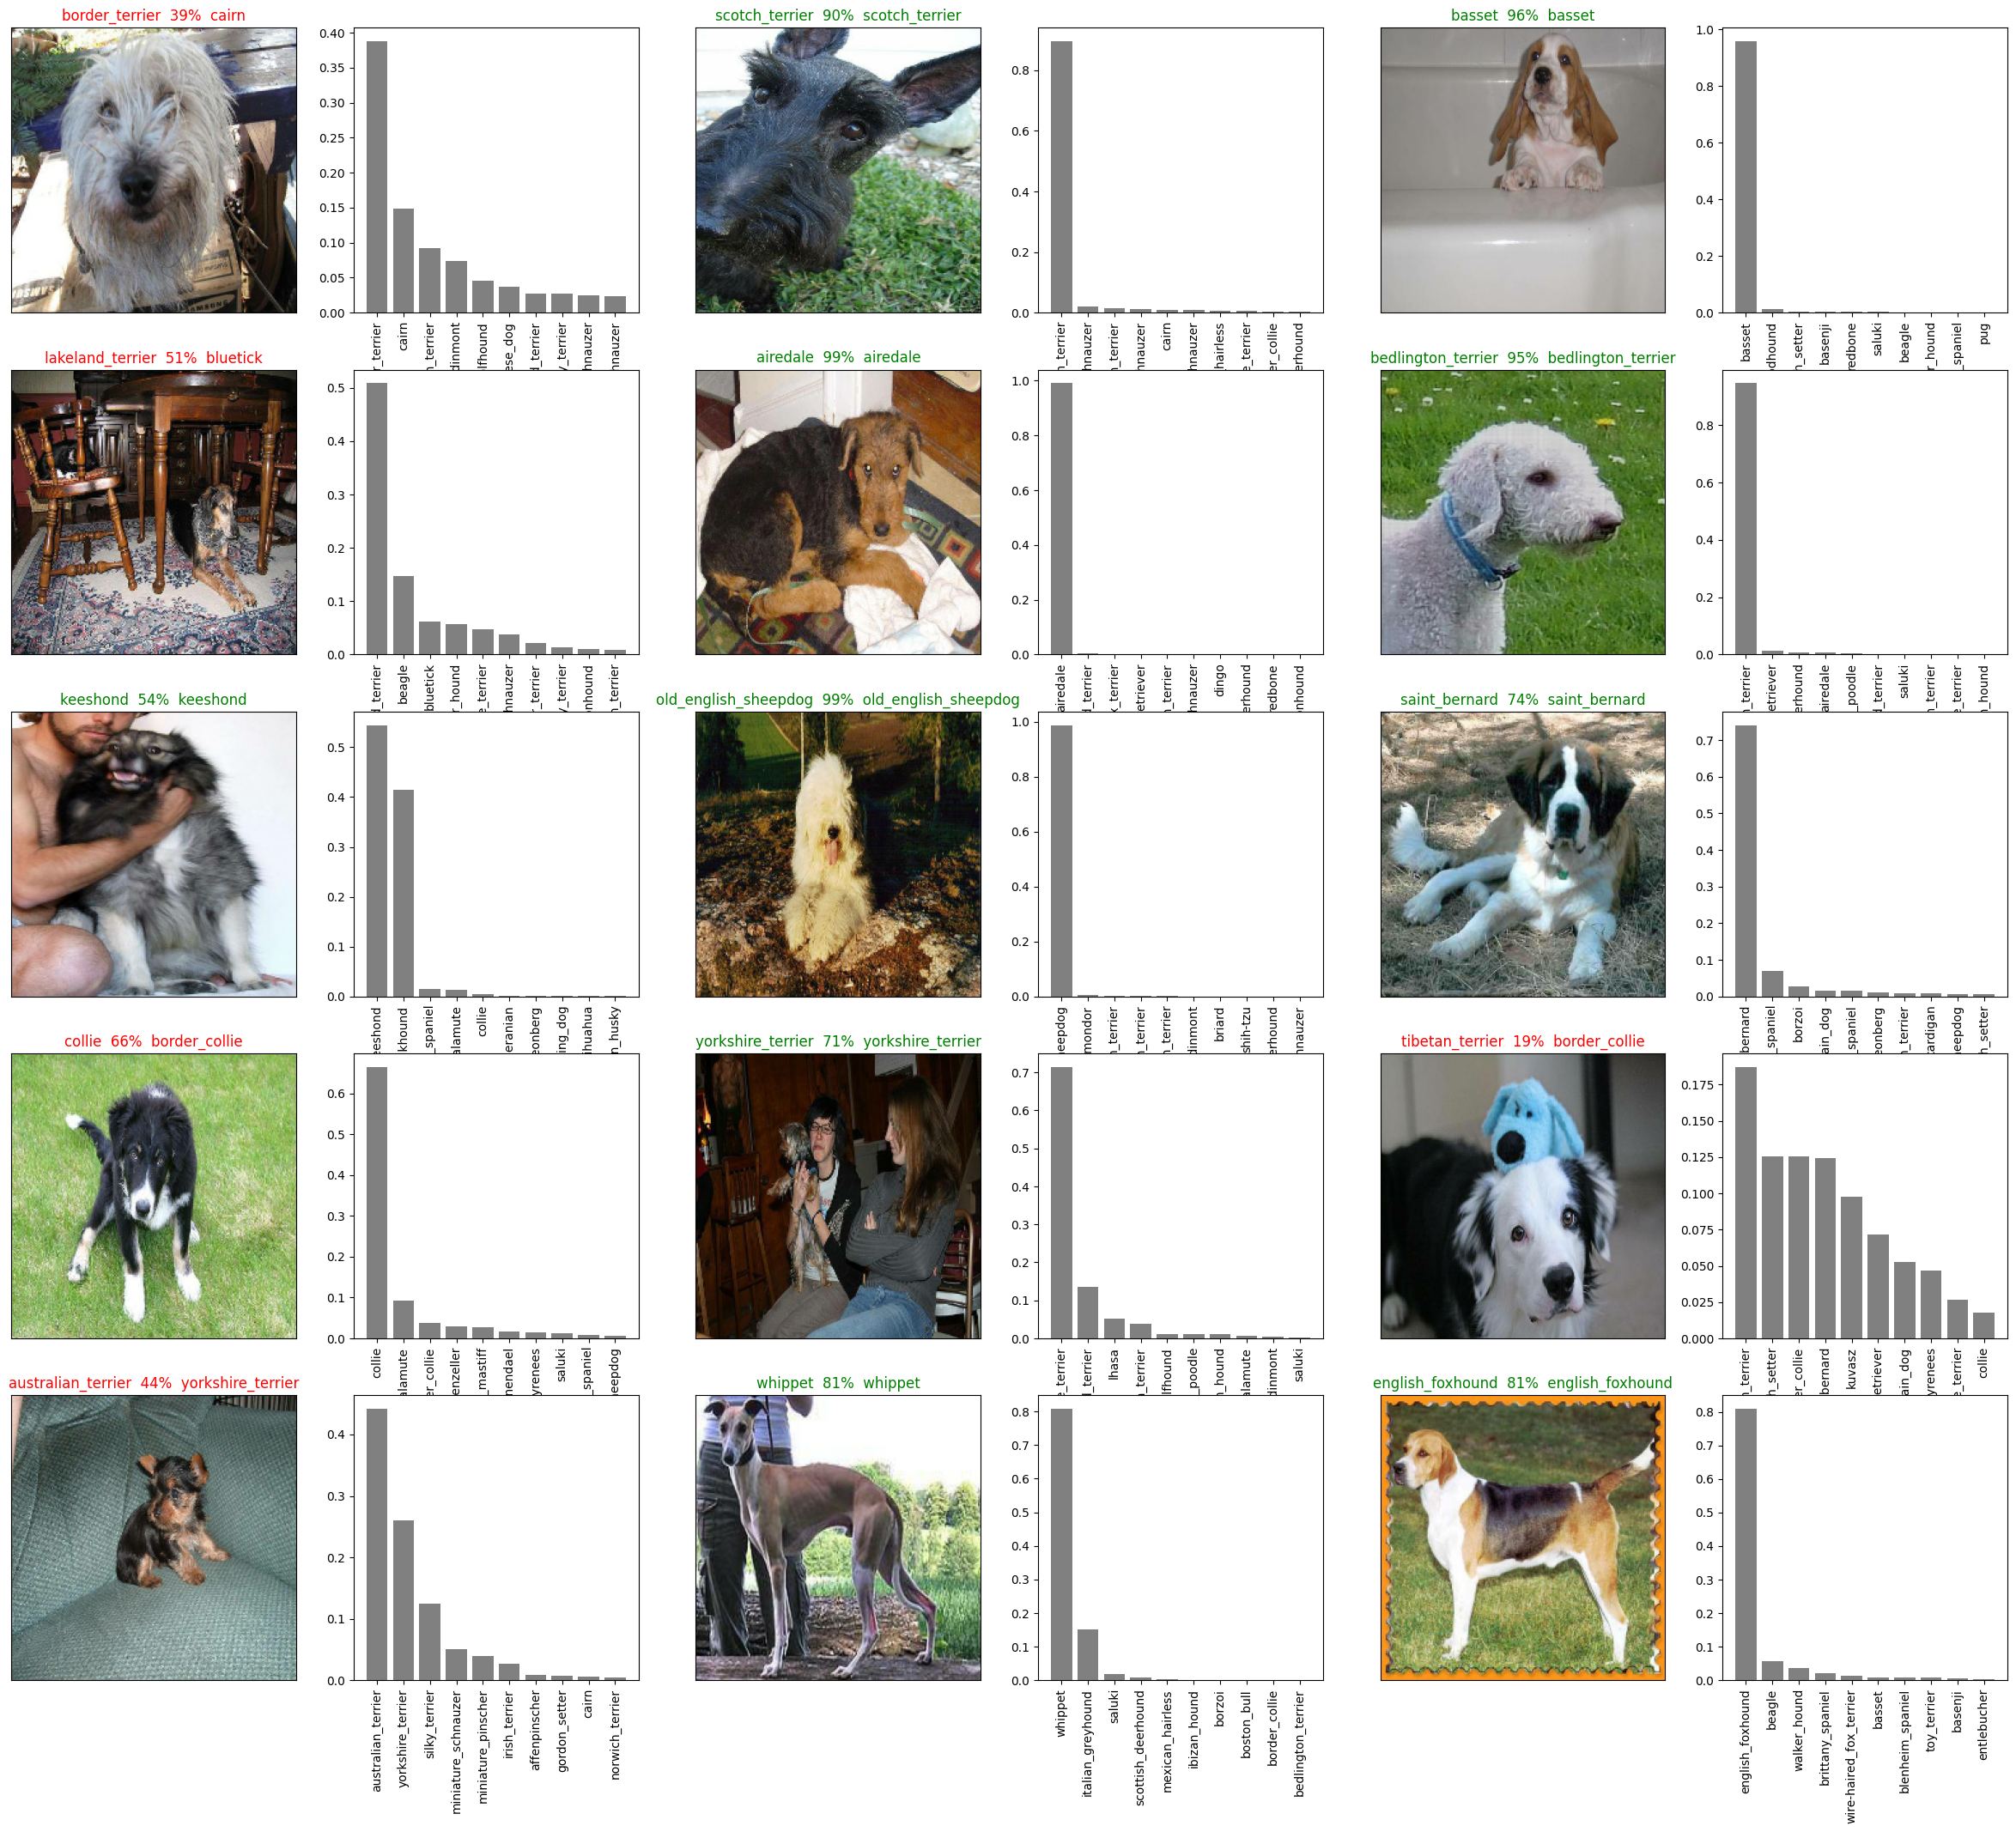

In [11]:
#Let's check out different predictions and their different values

i_multiplier = 0
num_rows = 5
num_cols = 3
num_images = num_rows * num_cols
plt.figure(figsize=(10*num_cols, 5*num_rows))

for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_pred(predictions, val_labels, val_images, i+i_multiplier)

  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_pred_conf(predictions, val_labels, i+i_multiplier)

plt.show()

In [12]:

#Saving and reloading a model
def save_model(model, suffix=None):
  '''
  Saves a given model in a models directory and appends a suffix (string)
  '''

  #Create a model directory pathname with current time
  modeldir = os.path.join('/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/', datetime.datetime.now().strftime('%Y%m%d-%H%M%s'))
  model_path = modeldir + '-' + suffix + '.h5'
  print(f'Saving model to {model_path}')
  model.save(model_path)
  return model_path





In [13]:
def load_model(model_path):
  #Loads a saved model from a specific path
  print(f'Loading model from {model_path}')
  model = tf_keras.models.load_model(model_path, custom_objects={'KerasLayer':hub.KerasLayer})

  return model



In [14]:
save_model(model, '1000-images-mobilenetv2-Adam')

Saving model to /Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250511-10391746940162-1000-images-mobilenetv2-Adam.h5


/opt/anaconda3/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


'/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250511-10391746940162-1000-images-mobilenetv2-Adam.h5'

In [16]:
load_1000_image_model = load_model('/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250511-10391746940162-1000-images-mobilenetv2-Adam.h5')

Loading model from /Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250511-10391746940162-1000-images-mobilenetv2-Adam.h5


In [17]:
#Evaluate the loaded model
load_1000_image_model.evaluate(val_data)

7/7 [==============================] - 1s 154ms/step - loss: 1.2315 - accuracy: 0.6900


[1.2314647436141968, 0.6899999976158142]

In [18]:
full_data = create_data_batches(x,y)
full_model = create_model()
full_model_tensorboard = create_tensorboard_callback()
full_model_early_stopping = tf_keras.callbacks.EarlyStopping(monitor='accuracy', patience=3)

Create training data batches...
Building model with   https://kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/1


In [19]:
#Fit the full model to the full data
full_model.fit(x=full_data, epochs=NUM_EPOCHS, callbacks=[full_model_tensorboard, full_model_early_stopping])


Epoch 1/100
320/320 [==============================] - 60s 184ms/step - loss: 1.3355 - accuracy: 0.6690
Epoch 2/100
320/320 [==============================] - 61s 190ms/step - loss: 0.3959 - accuracy: 0.8839
Epoch 3/100
320/320 [==============================] - 69s 214ms/step - loss: 0.2396 - accuracy: 0.9324
Epoch 4/100
320/320 [==============================] - 73s 228ms/step - loss: 0.1516 - accuracy: 0.9652
Epoch 5/100
320/320 [==============================] - 72s 224ms/step - loss: 0.1081 - accuracy: 0.9782
Epoch 6/100
320/320 [==============================] - 74s 230ms/step - loss: 0.0770 - accuracy: 0.9863
Epoch 7/100
320/320 [==============================] - 75s 236ms/step - loss: 0.0585 - accuracy: 0.9913
Epoch 8/100
320/320 [==============================] - 83s 259ms/step - loss: 0.0463 - accuracy: 0.9932
Epoch 9/100
320/320 [==============================] - 94s 294ms/step - loss: 0.0373 - accuracy: 0.9959
Epoch 10/100
320/320 [==============================] - 86s 269m

In [20]:
save_model(full_model, 'full-image-set-mobilenetv2-Adam')

Saving model to /Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250511-11051746941710-full-image-set-mobilenetv2-Adam.h5


'/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250511-11051746941710-full-image-set-mobilenetv2-Adam.h5'

In [21]:
loaded_full_model = load_model('/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250511-11051746941710-full-image-set-mobilenetv2-Adam.h5')


Loading model from /Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/models/20250511-11051746941710-full-image-set-mobilenetv2-Adam.h5


In [22]:
test_path = '/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog-breed-identification/test/'
test_filenames = [test_path + fname for fname in os.listdir(test_path)]

test_data = create_data_batches(test_filenames, test_data=True)

test_predictions = loaded_full_model.predict(test_data, verbose=1)

Creating test data batches...
324/324 [==============================] - 67s 206ms/step


In [23]:
#Save predictions to a numpy array
np.savetxt('/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog_preds.txt', test_predictions, delimiter=',')


In [24]:
#Load predictions from txt file
test_predictions = np.loadtxt('/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/dog_preds.txt', delimiter=',')
test_predictions

array([[1.24644309e-10, 5.02571311e-07, 1.15312160e-09, ...,
        4.30608316e-06, 3.24521687e-10, 3.51193185e-12],
       [4.26648790e-03, 7.34384928e-04, 2.84853900e-06, ...,
        1.47473486e-06, 2.20552602e-06, 9.20292536e-08],
       [5.06810025e-08, 2.03982914e-10, 2.05225946e-13, ...,
        4.06833231e-13, 4.09255442e-12, 1.74352568e-12],
       ...,
       [1.17919576e-08, 2.94339372e-07, 1.07208916e-06, ...,
        7.24546262e-05, 1.38395713e-08, 5.79920290e-08],
       [6.28756769e-12, 6.24576391e-10, 1.71781922e-10, ...,
        7.28033883e-11, 4.91567065e-10, 2.15456125e-11],
       [4.08889093e-07, 2.42123512e-08, 3.97589559e-07, ...,
        1.54118254e-06, 9.18874488e-09, 5.82161097e-10]])

In [25]:
import pandas as pd
#Create a pandas DataFrame with empty columns
preds_df = pd.DataFrame(columns=['id'] + list(unique_breeds))
preds_df.head()

#Append the test image ID's to predictions DataFrame
test_ids = [os.path.splitext(path)[0] for path in os.listdir(test_path)]
preds_df['id'] = test_ids
preds_df[list(unique_breeds)] = test_predictions
preds_df.head()

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,266490a2b053a4a3bf68e779f28fb5a9,1.246443e-10,5.025713e-07,1.153122e-09,2.857852e-07,4.570308e-12,8.228859e-07,9.203420e-13,2.153068e-11,3.248323e-04,...,3.301141e-10,1.595230e-09,2.892853e-05,1.203894e-06,5.283289e-08,1.250881e-12,3.530346e-09,4.306083e-06,3.245217e-10,3.511932e-12
1,dae9fd18836d8df20989ef0101771d4b,4.266488e-03,7.343849e-04,2.848539e-06,5.660128e-07,4.381619e-07,3.230321e-08,8.083229e-03,4.817764e-09,2.279206e-07,...,2.612923e-07,1.356984e-06,2.012751e-07,4.783054e-05,4.835366e-05,9.072632e-11,2.320148e-06,1.474735e-06,2.205526e-06,9.202925e-08
2,079a40f22b0fad9a66f76797b62bb930,5.068100e-08,2.039829e-10,2.052259e-13,5.929070e-10,1.222396e-11,2.290747e-11,2.096330e-11,1.602549e-11,8.106095e-12,...,1.413095e-12,1.714627e-11,3.562455e-12,7.900641e-11,2.468484e-11,7.684214e-13,1.112968e-12,4.068332e-13,4.092554e-12,1.743526e-12
3,ab8462f9a501d362041d47582fddc9ad,1.183892e-09,1.628196e-08,9.957105e-12,1.692313e-08,1.323124e-11,1.113366e-08,8.626807e-09,6.192692e-12,2.089109e-09,...,1.655041e-09,2.189918e-10,3.085453e-10,3.388930e-08,3.832151e-11,7.975955e-08,1.866495e-10,8.084411e-11,1.053157e-12,3.856539e-07
4,8895089b432e020cc42e6262b5a1c2dd,4.695566e-11,5.918368e-10,1.027812e-08,2.316618e-11,3.991667e-09,1.145614e-09,1.345218e-07,3.989120e-04,5.607772e-06,...,2.943529e-09,2.397125e-08,9.912082e-10,8.907322e-11,3.672030e-10,1.805297e-07,3.598189e-08,4.412429e-08,5.148813e-08,7.311635e-11


In [26]:
preds_df.to_csv('/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/full_model_submission.csv')

In [27]:
import os
custom_path = '/Users/spandankar/Documents/Placement course/AI ML DS/DEEP LEARNING/Dog Photos/'

custom_image_paths = [custom_path + fname for fname in os.listdir(custom_path)]

#Turn custom images into batch data sets
custom_data = create_data_batches(custom_image_paths, test_data=True)

#Make predictions
custom_preds = loaded_full_model.predict(custom_data)

Creating test data batches...
1/1 [==============================] - 0s 143ms/step


In [28]:
#Get custom image prediction labels
custom_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]

custom_images = []

#Loop through unbatched data
for image in custom_data.unbatch().as_numpy_iterator():
    custom_images.append(image)



2025-05-11 11:08:24.352786: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


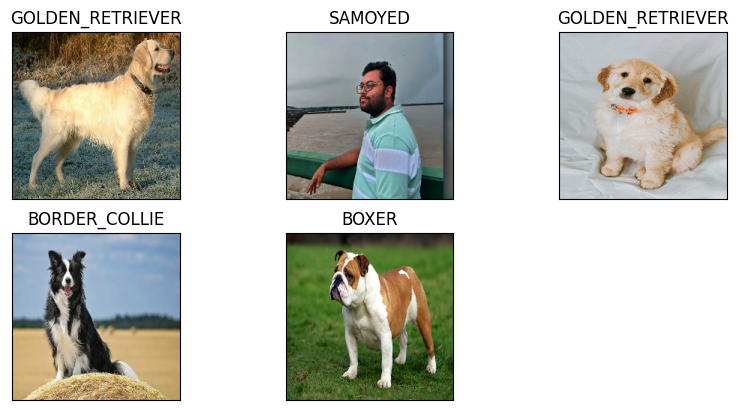

In [29]:
#Check custom image predictions
plt.figure(figsize=(10,10))

for i, image in enumerate(custom_images):
    plt.subplot(4,3,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.title(custom_labels[i].upper())
    plt.imshow(image)